# BÀI 6 NÂNG CAO: Dự báo SARIMA trên tập test và đánh giá

**Dataset:** AirPassengers, 144 quan sát (1949-01 → 1960-12), s = 12. Chia 80/20: 115 train / 29 test (test từ 1958-08).

**Phân biệt với bài 5:** bài 5 fit trên train và dự báo 12 tháng tương lai (1961, không có actual). Bài 6 dự báo đúng 29 tháng test (1958-08 → 1960-12, **có actual**) để tính MAE / RMSE / MAPE, kèm ARIMA(0,1,1) baseline để so sánh.

**Bàn giao cho bài 7:** `sarima_pred`, `sarima_ci`, `sarima_metrics`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA

def doc_air():
    """Ưu tiên file trong repo; không có thì đọc URL (giống Bài 4)."""
    for p in [Path("data/raw/airline-passengers.csv"), Path("../data/raw/airline-passengers.csv")]:
        if p.is_file():
            print("Đọc file:", p)
            return pd.read_csv(p)
    print("Đọc URL")
    return pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv")

## 1. Log và chia train/test

Log như Bài 3–5 (biên độ mùa vụ tăng theo mức chuỗi). Chia 80/20 theo thời gian, không shuffle — nhìn test trước khi chọn mô hình là rò rỉ dữ liệu.

In [2]:
df = doc_air()
df["Month"] = pd.to_datetime(df["Month"])
y = df.set_index("Month")["Passengers"].sort_index().asfreq("MS")

ly = np.log(y)
k = int(len(ly) * 0.8)
train_data, test_data = ly.iloc[:k], ly.iloc[k:]
assert len(train_data) == 115 and len(test_data) == 29
print(f"Train: {len(train_data)} tháng ({train_data.index.min().date()} → {train_data.index.max().date()})")
print(f"Test : {len(test_data)} tháng ({test_data.index.min().date()} → {test_data.index.max().date()})")

Đọc file: ..\data\raw\airline-passengers.csv
Train: 115 tháng (1949-01-01 → 1958-07-01)
Test : 29 tháng (1958-08-01 → 1960-12-01)


## 2. Fit SARIMA và ARIMA trên tập train

Cùng order như bài 5: `SARIMA(0,1,1)(0,1,1)₁₂` và ARIMA(0,1,1) baseline. Notebook này chạy riêng kernel nên fit lại; nếu gộp với bài 5 thì dùng thẳng `results` và `model_arima_fit`.

In [3]:
sarima_fit = SARIMAX(train_data, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit()
arima_fit  = ARIMA(train_data, order=(0, 1, 1)).fit()
assert sarima_fit.mle_retvals["converged"] and arima_fit.mle_retvals["converged"]

use_log_sarima = True   # model học trên log → mọi dự báo/metric phải np.exp về thang gốc
print(f"SARIMA AIC {sarima_fit.aic:.2f} | BIC {sarima_fit.bic:.2f}")
print(f"ARIMA  AIC {arima_fit.aic:.2f} | BIC {arima_fit.bic:.2f}")
# AIC hai mô hình không so trực tiếp được (SARIMA có D=1, likelihood trên chuỗi khác) — so bằng sai số bên dưới

SARIMA AIC -372.17 | BIC -364.30
ARIMA  AIC -193.43 | BIC -187.96


## 3. Dự báo 29 tháng test

Điểm dự báo + khoảng tin cậy 95%, `np.exp` về thang gốc.

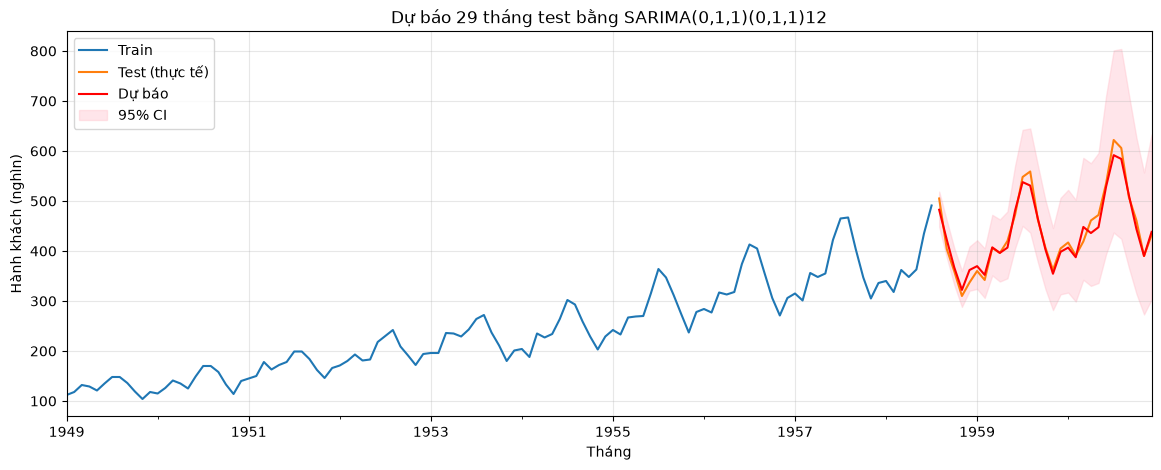

In [4]:
test_actual = np.exp(test_data)

fc = sarima_fit.get_forecast(steps=len(test_data))
sarima_pred = pd.Series(np.exp(fc.predicted_mean.to_numpy()), index=test_data.index)
sarima_ci   = pd.DataFrame(np.exp(fc.conf_int().to_numpy()), index=test_data.index,
                           columns=["lower", "upper"])

fig, ax = plt.subplots(figsize=(14, 5))
np.exp(train_data).plot(ax=ax, label="Train")
test_actual.plot(ax=ax, label="Test (thực tế)")
sarima_pred.plot(ax=ax, label="Dự báo", color="red")
ax.fill_between(sarima_ci.index, sarima_ci["lower"], sarima_ci["upper"],
                color="pink", alpha=0.4, label="95% CI")
ax.set_title("Dự báo 29 tháng test bằng SARIMA(0,1,1)(0,1,1)12")
ax.set_xlabel("Tháng"); ax.set_ylabel("Hành khách (nghìn)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 4. Sai số trên tập test

MAE (đơn vị gốc, dễ hiểu), RMSE (phạt nặng sai số lớn), MAPE (%). Đều tính trên thang gốc sau `np.exp`.

In [5]:
def sai_so(act, pred):
    err = act - pred
    return {"MAE":  err.abs().mean(),
            "RMSE": np.sqrt((err ** 2).mean()),
            "MAPE": (err.abs() / act).mean() * 100}

arima_pred = pd.Series(np.exp(arima_fit.get_forecast(len(test_data)).predicted_mean.to_numpy()),
                       index=test_data.index)
sarima_metrics = sai_so(test_actual, sarima_pred)
arima_metrics  = sai_so(test_actual, arima_pred)

err_s = (test_actual - sarima_pred).abs()
print(f"SARIMA sai lệch lớn nhất: {err_s.idxmax().date()} = {err_s.max():.2f} "
      f"(thực tế {test_actual[err_s.idxmax()]:.0f}, dự báo {sarima_pred[err_s.idxmax()]:.1f})")

pd.DataFrame({"SARIMA(0,1,1)(0,1,1)12": sarima_metrics, "ARIMA(0,1,1)": arima_metrics}).T.round(2)

SARIMA sai lệch lớn nhất: 1960-07-01 = 30.35 (thực tế 622, dự báo 591.7)


,MAE,RMSE,MAPE
"SARIMA(0,1,1)(0,1,1)12",12.61,15.68,2.83
"ARIMA(0,1,1)",86.72,99.05,21.69


**Kết luận bài 6:** SARIMA(0,1,1)(0,1,1)₁₂ dự báo 29 tháng test với **MAE 12.61 | RMSE 15.68 | MAPE 2.83%** — giảm MAE ~85% so với ARIMA(0,1,1) (86.72 / 99.05 / 21.69%). Thành phần mùa vụ (P,D,Q)₁₂ chính là phần ARIMA bỏ sót. Sai lệch lớn nhất 30.35 tại 07/1960 (thực tế 622, dự báo 591.7) — đúng tháng cao điểm.

Bàn giao bài 7: `sarima_pred`, `sarima_ci`, `sarima_metrics`, `test_actual`, `use_log_sarima`.